In [ ]:
import os
import pandas as pd
from openai import OpenAI
from dotenv import load_dotenv
from tqdm import tqdm
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from nltk.tokenize import word_tokenize
from bert_score import score as bert_score
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_rel
import scipy.stats as stats
# Load Toxic-BERT model and tokenizer
model_name = "unitary/toxic-bert"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

c:\Users\Yang Qing\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:797: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


# Read in simulated notes

In [ ]:
def read_simulated_notes(file_path):
    """
    Reads files from subfolders in the given directory into a pandas DataFrame.
    
    Args:
        file_path (str): The path to the folder containing subfolders with notes.

    Returns:
        pd.DataFrame: A DataFrame with columns 'file_name', 'note_1' to 'note_5'.
    """
    # Initialize an empty DataFrame
    data = {'file_name': []}
    for i in range(1, 6):
        data[f'note_{i}'] = []

    # Iterate over each subfolder (1-5)
    for i in range(1, 6):
        subfolder_path = os.path.join(file_path, str(i))
        if not os.path.exists(subfolder_path):
            raise ValueError(f"Subfolder {subfolder_path} does not exist.")
        
        # Read all files in the subfolder
        for file_name in os.listdir(subfolder_path):
            full_path = os.path.join(subfolder_path, file_name)
            if os.path.isfile(full_path):
                # Extract the first 16 characters of the file name
                trimmed_name = file_name[-20:-4]
                
                # Read the content of the file
                with open(full_path, 'r', encoding='utf-8') as file:
                    content = file.read()
                
                # Append the data to the dictionary
                if trimmed_name not in data['file_name']:
                    data['file_name'].append(trimmed_name)
                    for col in range(1, 6):
                        data[f'note_{col}'].append(None)
                row_idx = data['file_name'].index(trimmed_name)
                data[f'note_{i}'][row_idx] = content

    # Convert the dictionary into a DataFrame
    df = pd.DataFrame(data)
    return df

In [ ]:
# Example usage:
df = read_simulated_notes(r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Simulation\Robustness simulation\Simulated_notes\masked_simulated_notes")
df.head(10)

,file_name,note_1,note_2,note_3,note_4,note_5
0,DC0001 - DPt0411,**Subjective:**\nThe patient reports improveme...,**Subjective:**\n- The patient reports feeling...,**Subjective:**\nThe patient reports feeling o...,**Subjective:**\nThe patient reports feeling g...,**Subjective:**\n- The patient reports feeling...
1,DC0026 - DPt0326,**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\nThe patient reports a complex...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**SOAP Note Summary:**\n\n**Subjective:**\n- T...,"**Subjective:**\nThe patient, identified as Pe..."
2,DC0026 - DPt0529,**Subjective:**\nThe patient is 17 weeks pregn...,**Subjective:**\n- The patient is 17 weeks pre...,**SOAP Note Summary**\n\n**Subjective:**\n- Th...,**Subjective:**\n- The patient is 17 weeks pre...,**SOAP Note**\n\n**Subjective:**\n- Patient is...
3,DC0027 - DPt0596,**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\n- The patient is here for a n...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**SOAP Note**\n\n**Subjective:** \n- This is ...,**Subjective:**\n- The patient is here for a n...
4,DC0028 - DPt0506,**Subjective:**\nThe patient is pregnant with ...,**Subjective:**\n- The patient is currently pr...,**Subjective:**\nThe patient is currently preg...,**Subjective:** \n- The patient is pregnant w...,**Subjective:**\n- The patient is currently pr...
5,DC0033 - DPt0530,**Subjective:**\n- The patient reported having...,**Subjective:**\nThe patient reports that she ...,**SOAP Note**\n\n**Subjective:**\nThe patient ...,**Subjective:**\nThe patient reports that ever...,**Subjective:**\nThe patient reports that ever...
6,DC0033 - DPt0564,**Subjective:**\nThe patient expressed concern...,**Subjective:** \nThe patient apologized for ...,**Subjective:**\n- The patient apologized for ...,**Subjective:**\n- The patient expressed apolo...,**Subjective:** \nThe patient expressed apolo...
7,DC0034 - DPt0329,**Subjective:**\nThe patient reports feeling t...,**Subjective:** \nThe patient reports feeling...,**SOAP Note Summary**\n\n**Subjective:**\nThe ...,**SOAP Note:**\n\n**Subjective:**\n- The patie...,**Subjective:**\nThe patient reports feeling t...
8,DC0042 - DPt0510,**SOAP Note**\n\n**Patient Name:** [Redacted] ...,**SOAP Note:**\n\n**Subjective:**\n- The patie...,**Subjective:**\n- The patient reports cutting...,**SOAP Note Summary**\n\n**Subjective:**\n- Pa...,**SOAP Note**\n\n**Subjective:**\n- The patien...
9,DC0042 - DPt0527,**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\nThe patient is approximately ...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**SOAP Note**\n\n**Subjective:**\n- Patient is...,**SOAP Note**\n\n**Subjective:**\n- The patien...


In [ ]:
def read_reference_texts(reference_dir):
    """
    Reads text files in a directory and creates a DataFrame with two columns:
    - 'file_id': first 16 characters of each file name
    - 'content': content of the corresponding file

    Parameters:
        reference_dir (str): The directory containing reference text files.

    Returns:
        pd.DataFrame: DataFrame with file identifiers and file contents.
    """
    data = []

    # Loop through files in the directory
    for file_name in os.listdir(reference_dir):
        file_path = os.path.join(reference_dir, file_name)
        # Check if the path is a file
        if os.path.isfile(file_path):
            try:
                # Extract the first 16 characters of the file name
                file_id = file_name[:16]
                # Read the content of the file with multiple encodings fallback
                try:
                    with open(file_path, 'r', encoding='utf-8') as file:
                        content = file.read()
                except UnicodeDecodeError:
                    with open(file_path, 'r', encoding='cp1252') as file:  # Common fallback encoding
                        content = file.read()
                # Append to data list
                data.append({'file_name': file_id, 'reference_text': content})
            except Exception as e:
                print(f"Error reading {file_name}: {e}")

    # Create DataFrame
    df = pd.DataFrame(data)
    return df

In [ ]:
# Example usage
reference_dir = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Gold standard note"
reference_df = read_reference_texts(reference_dir)
df['file_name'] = df['file_name'].str[:16]
df_with_reference = pd.merge(reference_df, df, on='file_name', how='inner')
df_with_reference.head(10)

,file_name,reference_text,note_1,note_2,note_3,note_4,note_5
0,DC0001 - DPt0411,**SOAP Note**\n\n**Subjective:**\n- Patient re...,**Subjective:**\nThe patient reports improveme...,**Subjective:**\n- The patient reports feeling...,**Subjective:**\nThe patient reports feeling o...,**Subjective:**\nThe patient reports feeling g...,**Subjective:**\n- The patient reports feeling...
1,DC0026 - DPt0326,**SOAP Note**\n\n**Patient Information:**\n- N...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\nThe patient reports a complex...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**SOAP Note Summary:**\n\n**Subjective:**\n- T...,"**Subjective:**\nThe patient, identified as Pe..."
2,DC0026 - DPt0529,"**Subjective:**\n- The patient, currently 17 w...",**Subjective:**\nThe patient is 17 weeks pregn...,**Subjective:**\n- The patient is 17 weeks pre...,**SOAP Note Summary**\n\n**Subjective:**\n- Th...,**Subjective:**\n- The patient is 17 weeks pre...,**SOAP Note**\n\n**Subjective:**\n- Patient is...
3,DC0027 - DPt0596,**SOAP Note:**\n\n**Patient:**\n- Name: Inform...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\n- The patient is here for a n...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**SOAP Note**\n\n**Subjective:** \n- This is ...,**Subjective:**\n- The patient is here for a n...
4,DC0028 - DPt0506,**SOAP Note**\n\n**Subjective:**\n- Patient is...,**Subjective:**\nThe patient is pregnant with ...,**Subjective:**\n- The patient is currently pr...,**Subjective:**\nThe patient is currently preg...,**Subjective:** \n- The patient is pregnant w...,**Subjective:**\n- The patient is currently pr...
5,DC0033 - DPt0530,**Subjective:**\n- The patient mentioned a pre...,**Subjective:**\n- The patient reported having...,**Subjective:**\nThe patient reports that she ...,**SOAP Note**\n\n**Subjective:**\nThe patient ...,**Subjective:**\nThe patient reports that ever...,**Subjective:**\nThe patient reports that ever...
6,DC0033 - DPt0564,**SOAP Note**\n\n**Patient Information:**\n- P...,**Subjective:**\nThe patient expressed concern...,**Subjective:** \nThe patient apologized for ...,**Subjective:**\n- The patient apologized for ...,**Subjective:**\n- The patient expressed apolo...,**Subjective:** \nThe patient expressed apolo...
7,DC0034 - DPt0329,**SOAP Note**\n\n**Patient Information:**\n- N...,**Subjective:**\nThe patient reports feeling t...,**Subjective:** \nThe patient reports feeling...,**SOAP Note Summary**\n\n**Subjective:**\nThe ...,**SOAP Note:**\n\n**Subjective:**\n- The patie...,**Subjective:**\nThe patient reports feeling t...
8,DC0042 - DPt0510,**SOAP Note**\n\n**Subjective:**\n- Patient is...,**SOAP Note**\n\n**Patient Name:** [Redacted] ...,**SOAP Note:**\n\n**Subjective:**\n- The patie...,**Subjective:**\n- The patient reports cutting...,**SOAP Note Summary**\n\n**Subjective:**\n- Pa...,**SOAP Note**\n\n**Subjective:**\n- The patien...
9,DC0042 - DPt0527,**SOAP Note**\n\n**Subjective:**\n- Patient is...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\nThe patient is approximately ...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**SOAP Note**\n\n**Subjective:**\n- Patient is...,**SOAP Note**\n\n**Subjective:**\n- The patien...


In [ ]:
# Function to calculate toxicity
def calculate_toxicity(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=512)
    with torch.no_grad():
        outputs = model(**inputs)
    scores = torch.nn.functional.softmax(outputs.logits, dim=-1)
    return scores[0][1].item()  # Toxicity score

# Function to calculate BLEU scores
def calculate_bleu(reference, candidate, n):
    smoothing = SmoothingFunction().method4
    weights = tuple([1.0 / n] * n) + tuple([0] * (4 - n))
    return sentence_bleu([reference.split()], candidate.split(), weights=weights, smoothing_function=smoothing)

# Function to calculate BLEU cumulative scores
def calculate_bleu_cumulative(reference, candidate):
    smoothing = SmoothingFunction().method4
    bleu1 = sentence_bleu([reference.split()], candidate.split(), weights=(1, 0, 0, 0), smoothing_function=smoothing)
    bleu2 = sentence_bleu([reference.split()], candidate.split(), weights=(0.5, 0.5, 0, 0), smoothing_function=smoothing)
    bleu3 = sentence_bleu([reference.split()], candidate.split(), weights=(0.33, 0.33, 0.33, 0), smoothing_function=smoothing)
    bleu4 = sentence_bleu([reference.split()], candidate.split(), weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothing)
    return bleu1, bleu2, bleu3, bleu4

# Function to calculate ROUGE scores
def calculate_rouge(reference, candidate):
    scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rouge3', 'rougeL'], use_stemmer=True)
    scores = scorer.score(reference, candidate)
    return scores

# Main function
def calculate_text_metrics(df, reference_col, text_cols):
    results = df.copy()
    for col in text_cols:
        rouge1_list, rouge2_list, rouge3_list, rougeL_list = [], [], [], []
        bleu1_list, bleu2_list, bleu3_list, bleu4_list = [], [], [], []
        bert_precision_list, bert_recall_list, bert_f1_list = [], [], []
        meteor_list = []
        toxicity_list = []

        for ref, text in tqdm(zip(results[reference_col], results[col]), total=len(results), desc=f"Processing {col}"):
            # ROUGE
            rouge_scores = calculate_rouge(ref, text)
            rouge1_list.append(rouge_scores['rouge1'].fmeasure)
            rouge2_list.append(rouge_scores['rouge2'].fmeasure)
            rouge3_list.append(rouge_scores['rouge3'].fmeasure)
            rougeL_list.append(rouge_scores['rougeL'].fmeasure)

            # BLEU
            bleu1_list.append(calculate_bleu(ref, text, 1))
            bleu2_list.append(calculate_bleu(ref, text, 2))
            bleu3_list.append(calculate_bleu(ref, text, 3))
            bleu4_list.append(calculate_bleu(ref, text, 4))

            # BLEU Cumulative
            bleu_cum1, bleu_cum2, bleu_cum3, bleu_cum4 = calculate_bleu_cumulative(ref, text)

            # METEOR
            try:
                meteor_list.append(meteor_score([ref.split()], text.split()))
            except:
                meteor_list.append(0.0)  # Handle empty texts

            # BERTScore
            P, R, F1 = bert_score([text], [ref], lang="en", verbose=False)
            bert_precision_list.append(P.mean().item())
            bert_recall_list.append(R.mean().item())
            bert_f1_list.append(F1.mean().item())

            # Toxicity
            toxicity_list.append(calculate_toxicity(text))

        # Append results as new columns
        results[f'{col}_rouge1'] = rouge1_list
        results[f'{col}_rouge2'] = rouge2_list
        results[f'{col}_rouge3'] = rouge3_list
        results[f'{col}_rougeL'] = rougeL_list
        results[f'{col}_bleu1'] = bleu1_list
        results[f'{col}_bleu2'] = bleu2_list
        results[f'{col}_bleu3'] = bleu3_list
        results[f'{col}_bleu4'] = bleu4_list
        results[f'{col}_meteor'] = meteor_list
        results[f'{col}_bert_precision'] = bert_precision_list
        results[f'{col}_bert_recall'] = bert_recall_list
        results[f'{col}_bert_f1'] = bert_f1_list
        results[f'{col}_toxicity'] = toxicity_list

    return results


In [ ]:
notes_columns = [col for col in df_with_reference.columns if 'note' in col]
# Run the `calculate_text_metrics` function for the notes columns
results_df = calculate_text_metrics(df_with_reference, reference_col='reference_text', text_cols=notes_columns)

results_df.head(10)

Processing note_1:   0%|          | 0/40 [00:00<?, ?it/s]c:\Users\Yang Qing\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:797: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.weight', 'roberta.pooler.dense.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Processing note_1:   2%|▎         | 1/40 [00:12<08:11, 12.59s/it]Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.weight', 'roberta.pooler.dense.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Proc

,file_name,reference_text,note_1,note_2,note_3,note_4,note_5,note_1_rouge1,note_1_rouge2,note_1_rouge3,...,note_5_rougeL,note_5_bleu1,note_5_bleu2,note_5_bleu3,note_5_bleu4,note_5_meteor,note_5_bert_precision,note_5_bert_recall,note_5_bert_f1,note_5_toxicity
0,DC0001 - DPt0411,**SOAP Note**\n\n**Subjective:**\n- Patient re...,**Subjective:**\nThe patient reports improveme...,**Subjective:**\n- The patient reports feeling...,**Subjective:**\nThe patient reports feeling o...,**Subjective:**\nThe patient reports feeling g...,**Subjective:**\n- The patient reports feeling...,0.543478,0.155313,0.054645,...,0.266118,0.379114,0.195595,0.119598,0.083430,0.292543,0.879465,0.867159,0.873268,0.070652
1,DC0026 - DPt0326,**SOAP Note**\n\n**Patient Information:**\n- N...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\nThe patient reports a complex...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**SOAP Note Summary:**\n\n**Subjective:**\n- T...,"**Subjective:**\nThe patient, identified as Pe...",0.594816,0.166895,0.046639,...,0.236943,0.393120,0.173253,0.084010,0.041392,0.285141,0.873023,0.873674,0.873348,0.065244
2,DC0026 - DPt0529,"**Subjective:**\n- The patient, currently 17 w...",**Subjective:**\nThe patient is 17 weeks pregn...,**Subjective:**\n- The patient is 17 weeks pre...,**SOAP Note Summary**\n\n**Subjective:**\n- Th...,**Subjective:**\n- The patient is 17 weeks pre...,**SOAP Note**\n\n**Subjective:**\n- Patient is...,0.605974,0.245364,0.100143,...,0.307494,0.482452,0.285891,0.175789,0.110198,0.339337,0.892770,0.889441,0.891102,0.053582
3,DC0027 - DPt0596,**SOAP Note:**\n\n**Patient:**\n- Name: Inform...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**Subjective:**\n- The patient is here for a n...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**SOAP Note**\n\n**Subjective:** \n- This is ...,**Subjective:**\n- The patient is here for a n...,0.555556,0.183024,0.058511,...,0.288608,0.419847,0.251238,0.164920,0.111572,0.334288,0.884823,0.875711,0.880244,0.051075
4,DC0028 - DPt0506,**SOAP Note**\n\n**Subjective:**\n- Patient is...,**Subjective:**\nThe patient is pregnant with ...,**Subjective:**\n- The patient is currently pr...,**Subjective:**\nThe patient is currently preg...,**Subjective:** \n- The patient is pregnant w...,**Subjective:**\n- The patient is currently pr...,0.602410,0.224525,0.093588,...,0.285192,0.406667,0.239006,0.145291,0.080169,0.322461,0.898533,0.890513,0.894505,0.067121
5,DC0033 - DPt0530,**Subjective:**\n- The patient mentioned a pre...,**Subjective:**\n- The patient reported having...,**Subjective:**\nThe patient reports that she ...,**SOAP Note**\n\n**Subjective:**\nThe patient ...,**Subjective:**\nThe patient reports that ever...,**Subjective:**\nThe patient reports that ever...,0.631868,0.253444,0.104972,...,0.261753,0.459713,0.257172,0.137274,0.078533,0.324456,0.884856,0.877339,0.881081,0.063900
6,DC0033 - DPt0564,**SOAP Note**\n\n**Patient Information:**\n- P...,**Subjective:**\nThe patient expressed concern...,**Subjective:** \nThe patient apologized for ...,**Subjective:**\n- The patient apologized for ...,**Subjective:**\n- The patient expressed apolo...,**Subjective:** \nThe patient expressed apolo...,0.372215,0.060447,0.000000,...,0.154040,0.178594,0.064892,0.018797,0.008797,0.146134,0.829251,0.824657,0.826948,0.087424
7,DC0034 - DPt0329,**SOAP Note**\n\n**Patient Information:**\n- N...,**Subjective:**\nThe patient reports feeling t...,**Subjective:** \nThe patient reports feeling...,**SOAP Note Summary**\n\n**Subjective:**\nThe ...,**SOAP Note:**\n\n**Subjective:**\n- The patie...,**Subjective:**\nThe patient reports feeling t...,0.547974,0.173077,0.068522,...,0.188601,0.342645,0.152990,0.082572,0.042068,0.241724,0.849316,0.831596,0.840362,0.036214
8,DC0042 - DPt0510,**SOAP Note**\n\n**Subjective:**\n- Patient is...,**SOAP Note**\n\n**Patient Name:** [Redacted] ...,**SOAP Note:**\n\n**Subjective:**\n- The patie...,**Subjective:**\n- The patient reports cutting...,**S

# Save dataframe

In [ ]:
# Define the metrics
metrics = ['rouge1', 'rouge2', 'rouge3', 'rougeL', 'bleu1', 'bleu2', 'bleu3', 'bleu4', 'meteor', 
           'bert_precision', 'bert_recall', 'bert_f1', 'toxicity']

# Loop through metrics to calculate averages
for metric in metrics:
    # Extract columns for the current metric across notes_1 to notes_5
    cols = [f'note_{i}_{metric}' for i in range(1, 6)]
    # Check if the columns exist in the DataFrame to avoid errors
    existing_cols = [col for col in cols if col in results_df.columns]
    if existing_cols:  # Only compute if columns are present
        # Calculate the average
        avg_col_name = f'average_{metric}'
        results_df[avg_col_name] = results_df[existing_cols].mean(axis=1)

# Display the updated DataFrame
print(results_df)

           file_name                                     reference_text  \
0   DC0001 - DPt0411  **SOAP Note**\n\n**Subjective:**\n- Patient re...   
1   DC0026 - DPt0326  **SOAP Note**\n\n**Patient Information:**\n- N...   
2   DC0026 - DPt0529  **Subjective:**\n- The patient, currently 17 w...   
3   DC0027 - DPt0596  **SOAP Note:**\n\n**Patient:**\n- Name: Inform...   
4   DC0028 - DPt0506  **SOAP Note**\n\n**Subjective:**\n- Patient is...   
5   DC0033 - DPt0530  **Subjective:**\n- The patient mentioned a pre...   
6   DC0033 - DPt0564  **SOAP Note**\n\n**Patient Information:**\n- P...   
7   DC0034 - DPt0329  **SOAP Note**\n\n**Patient Information:**\n- N...   
8   DC0042 - DPt0510  **SOAP Note**\n\n**Subjective:**\n- Patient is...   
9   DC0042 - DPt0527  **SOAP Note**\n\n**Subjective:**\n- Patient is...   
10  DC0042 - DPt0609  **SOAP Note**\n\n**Patient:** Person 2\n\n**Da...   
11  DC0068 - DPt0567  **SOAP Note**\n\n**Subjective:**\n- Patient, M...   
12  DC0085 - DPt0631  **S

In [ ]:
# Define the save path
save_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\masked_simulation_results_df.csv"

# Save the DataFrame as a CSV file
results_df.to_csv(save_path, index=False)

print(f"DataFrame saved successfully to {save_path}")

DataFrame saved successfully to C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\masked_simulation_results_df.csv


In [ ]:
# Define the file path
file_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Datasets\direct_evaluation_repeated_results_df.csv"

# Read the CSV file
repeated_results_df = pd.read_csv(file_path)

# Display the first few rows of the DataFrame
repeated_results_df['gpt']

,file_name,llama_note_1,llama_note_2,llama_note_3,llama_note_4,llama_note_5,reference_text,transcript,gpt_note_1,gpt_note_2,...,llama_rougeL_average,llama_bleu1_average,llama_bleu2_average,llama_bleu3_average,llama_bleu4_average,llama_meteor_average,llama_bert_precision_average,llama_bert_recall_average,llama_bert_f1_average,llama_toxicity_average
0,DC0001 - DPt0411,Here is a summarized version of the transcript...,"Here is a summary of the transcript, classifie...",**Subjective:**\n\n* The patient has had a flu...,"Here is a summary of the transcript, categoriz...",Here is a summarized version of the transcript...,**SOAP Note**\n\n**Subjective:**\n- Patient re...,How are you doing today? I'm doing okay. Thank...,**Subjective:** \nThe patient reports experie...,**Subjective:**\n\n- The patient is experienci...,...,0.137605,0.147159,0.056163,0.024190,0.012093,0.130340,0.849068,0.819706,0.834122,0.078400
1,DC0026 - DPt0326,**Subjective**\n\n* The patient reports a stro...,**Subjective**\n\n* The patient has a 20-pack-...,**Subjective**\n\n* The patient describes her ...,**Subjective**\n\n* The patient is a female in...,Here is a summarized version of the transcript...,**SOAP Note**\n\n**Patient Information:**\n- N...,"How are you? I'm doing good. Um, we're all goo...",**Subjective:**\n\n- The patient is Person 6 a...,**Subjective:**\n- The patient is pregnant and...,...,0.151703,0.212833,0.090313,0.044168,0.024156,0.152473,0.850564,0.826471,0.838341,0.058725
2,DC0026 - DPt0529,"Here is a summary of the transcript, classifie...","Here is a summary of the transcript, classifie...",**Subjective**\n\n* The patient is a pregnant ...,Here is a summarized version of the transcript...,"Here is a summary of the transcript, classifie...","**Subjective:**\n- The patient, currently 17 w...","Hi, I'm Person 2. It's nice to meet you. How a...",**Subjective:**\n\n- The patient is 17 weeks p...,"**Subjective:**\n- Patient, Person 1, is curre...",...,0.198946,0.235391,0.116997,0.057203,0.031697,0.191841,0.862288,0.841152,0.851586,0.066684
3,DC0027 - DPt0596,"Here is a summary of the transcript, accuratel...","Here is a summary of the transcript, classifie...",**SOAP Summary**\n\n**Subjective:**\n\n* The p...,Here is a summarized version of the transcript...,"Here is a summary of the transcript, accuratel...",**SOAP Note:**\n\n**Patient:**\n- Name: Inform...,"Hello! Hi, how's it going?\nI have a student w...",**SOAP Note**\n\n**Subjective:**\n- The patien...,**SOAP Note**\n\n**Subjective:**\n- The patien...,...,0.166137,0.220904,0.087147,0.042638,0.019582,0.172535,0.852033,0.827380,0.839519,0.074676
4,DC0028 - DPt0506,"Here is a summary of the transcript, categoriz...",**Subjective**\n\n* The patient is pregnant wi...,**Subjective**\n\n* The patient is a pregnant ...,"Here is a summary of the transcript, classifie...","Here is a summary of the transcript, classifie...",**SOAP Note**\n\n**Subjective:**\n- Patient is...,Thank you guys. Thank you. Good morning. Good ...,**SOAP Note**\n\n**Subjective:**\n- The patien...,**SOAP Note**\n\n**Subjective:**\n- The patien...,...,0.242287,0.336540,0.156568,0.077735,0.038260,0.242377,0.877521,0.871393,0.874446,0.068116
5,DC0033 - DPt0530,"Here is a summary of the transcript, classifie...",Here is a summarized version of the transcript...,Here is a summarized version of the transcript...,Here is a summarized version of the transcript...,"Here is a summary of the transcript, classifie...",**Subjective:**\n- The patient mentioned a pre...,"How are you doing? Oh, good. How are you? I'm ...","**Subjective:** \nThe patient, who is current...",**Subjective:**\nThe patient reports that over...,...,0.162135,0.218160,0.087007,0.035654,0.018504,0.162794,0.862024,0.830617,0.846024,0.087728
6,DC0033 - DPt0564,**Subjective:**\n\nThe patient is a 10-year-ol...,**SOAP Summary**\n\n**Subjective:**\n\n* The 1...,Here is a summarized version of the transcript...,**Subjective**\n\nThe patient is a 10-year-old...,**Subjective:**

In [ ]:
filtered_columns = [col for col in repeated_results_df.columns if col.startswith('gpt_') and 
                    col.endswith('_average') ]
filtered_columns.append('file_name')
# Create the sub-DataFrame
gpt_results_df = repeated_results_df[filtered_columns]
gpt_results_df.head(5)

,gpt_rouge1_average,gpt_rouge2_average,gpt_rouge3_average,gpt_rougeL_average,gpt_bleu1_average,gpt_bleu2_average,gpt_bleu3_average,gpt_bleu4_average,gpt_meteor_average,gpt_bert_precision_average,gpt_bert_recall_average,gpt_bert_f1_average,gpt_toxicity_average,file_name
0,0.531417,0.154174,0.064831,0.252883,0.366468,0.189928,0.114263,0.074256,0.292090,0.871946,0.870817,0.871375,0.059462,DC0001 - DPt0411
1,0.540457,0.161739,0.060014,0.257313,0.415894,0.209618,0.112394,0.063525,0.297693,0.878715,0.872071,0.875378,0.056499,DC0026 - DPt0326
2,0.658220,0.306538,0.163683,0.383422,0.527231,0.353143,0.245788,0.180102,0.409547,0.911197,0.904661,0.907916,0.034005,DC0026 - DPt0529
3,0.557929,0.172753,0.063194,0.264386,0.416152,0.227847,0.128405,0.069797,0.308712,0.884241,0.876558,0.880373,0.047150,DC0027 - DPt0596
4,0.616887,0.236223,0.108832,0.327159,0.469219,0.283276,0.181457,0.122025,0.394580,0.901225,0.901129,0.901170,0.061792,DC0028 - DPt0506


In [ ]:
# Merge the dataframes on the 'file_name' column
merged_df = pd.merge(gpt_results_df, results_df, on='file_name', how='inner')

# Display the merged dataframe
merged_df.columns

Index(['gpt_rouge1_average', 'gpt_rouge2_average', 'gpt_rouge3_average',
       'gpt_rougeL_average', 'gpt_bleu1_average', 'gpt_bleu2_average',
       'gpt_bleu3_average', 'gpt_bleu4_average', 'gpt_meteor_average',
       'gpt_bert_precision_average', 'gpt_bert_recall_average',
       'gpt_bert_f1_average', 'gpt_toxicity_average', 'file_name',
       'reference_text', 'note_1', 'note_2', 'note_3', 'note_4', 'note_5',
       'note_1_rouge1', 'note_1_rouge2', 'note_1_rouge3', 'note_1_rougeL',
       'note_1_bleu1', 'note_1_bleu2', 'note_1_bleu3', 'note_1_bleu4',
       'note_1_meteor', 'note_1_bert_precision', 'note_1_bert_recall',
       'note_1_bert_f1', 'note_1_toxicity', 'note_2_rouge1', 'note_2_rouge2',
       'note_2_rouge3', 'note_2_rougeL', 'note_2_bleu1', 'note_2_bleu2',
       'note_2_bleu3', 'note_2_bleu4', 'note_2_meteor',
       'note_2_bert_precision', 'note_2_bert_recall', 'note_2_bert_f1',
       'note_2_toxicity', 'note_3_rouge1', 'note_3_rouge2', 'note_3_rouge3',
      

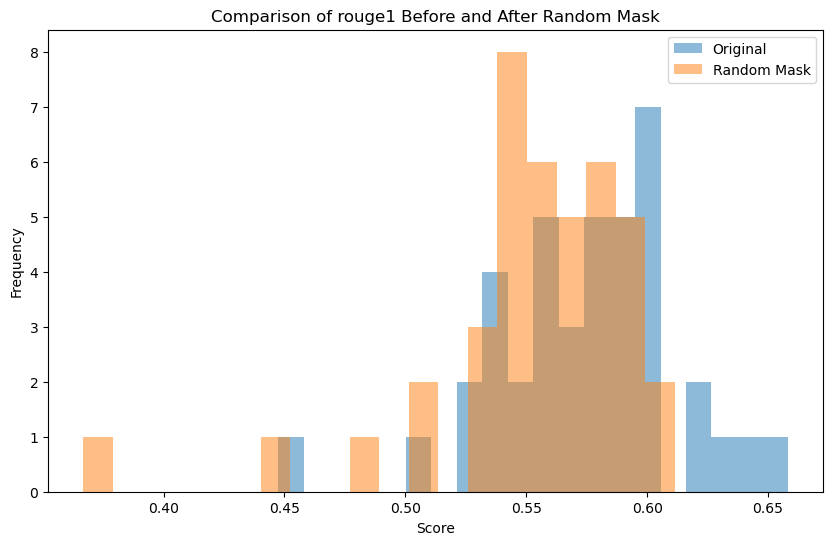

Metric: gpt_rouge1_average vs average_rouge1
T-statistic: 3.7536, P-value: 0.0006



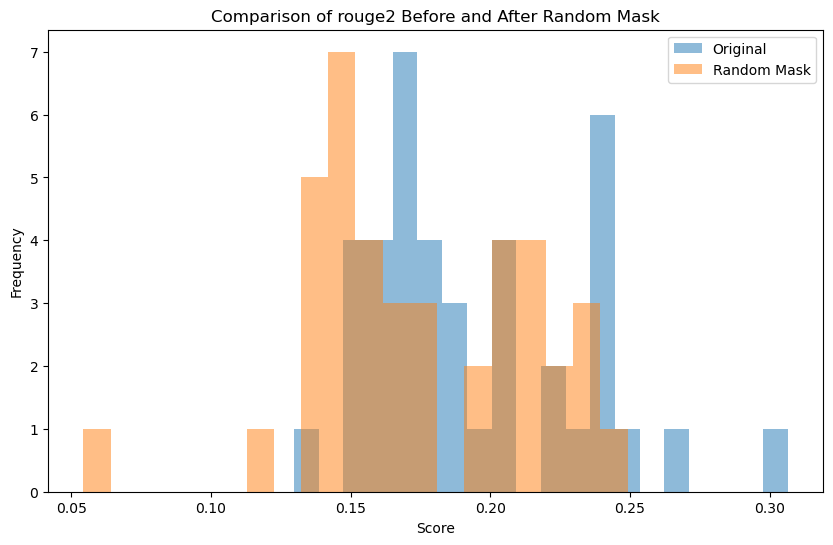

Metric: gpt_rouge2_average vs average_rouge2
T-statistic: 5.6219, P-value: 0.0000



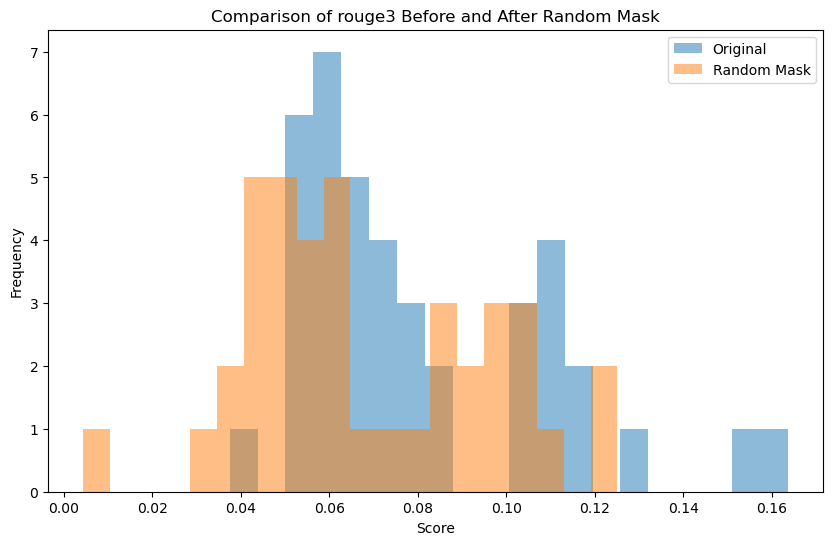

Metric: gpt_rouge3_average vs average_rouge3
T-statistic: 5.0905, P-value: 0.0000



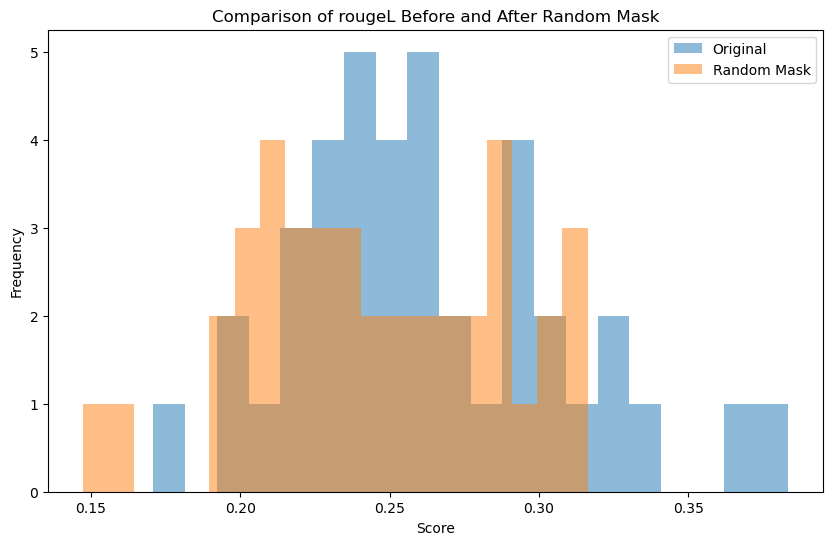

Metric: gpt_rougeL_average vs average_rougeL
T-statistic: 5.1390, P-value: 0.0000



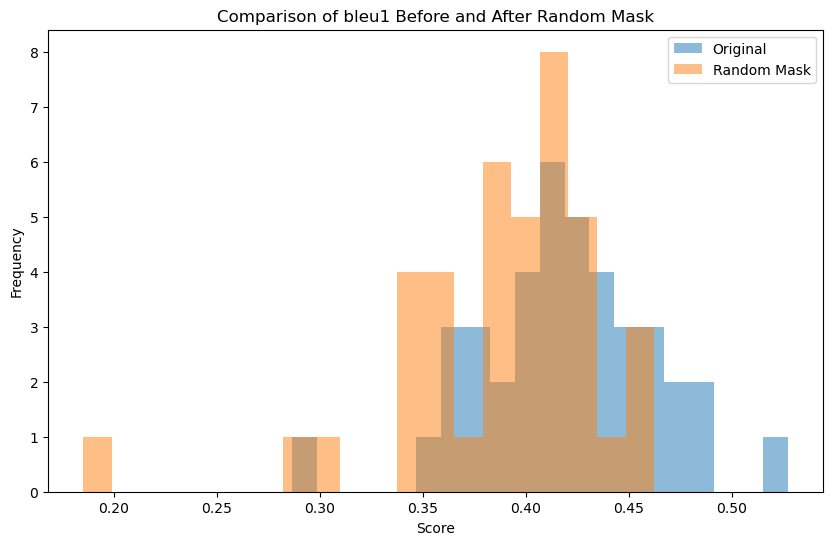

Metric: gpt_bleu1_average vs average_bleu1
T-statistic: 4.8078, P-value: 0.0000



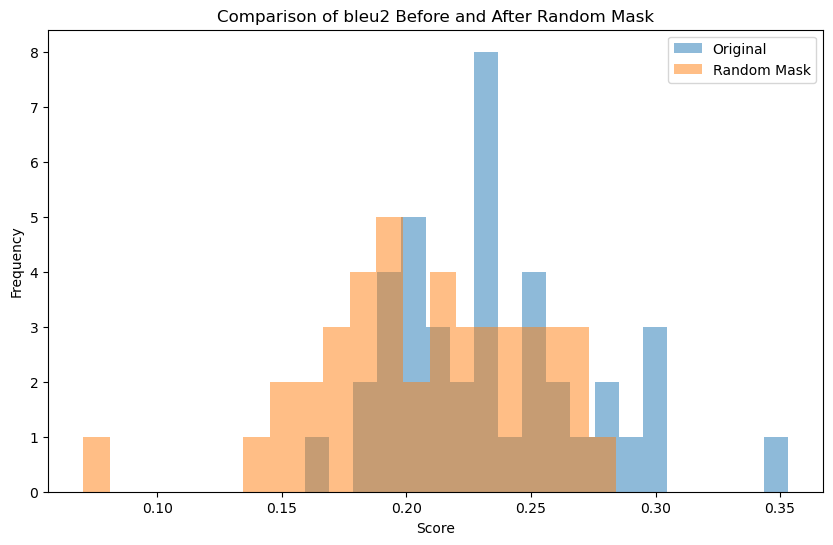

Metric: gpt_bleu2_average vs average_bleu2
T-statistic: 5.9971, P-value: 0.0000



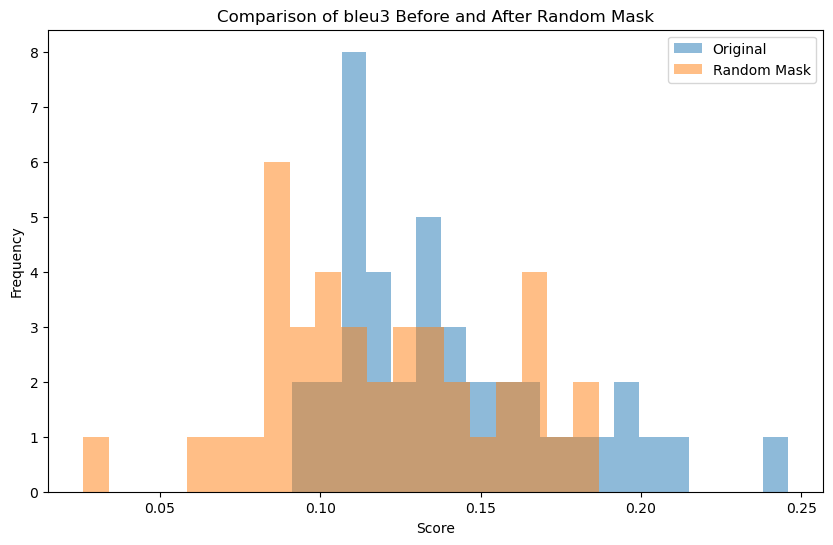

Metric: gpt_bleu3_average vs average_bleu3
T-statistic: 6.0170, P-value: 0.0000



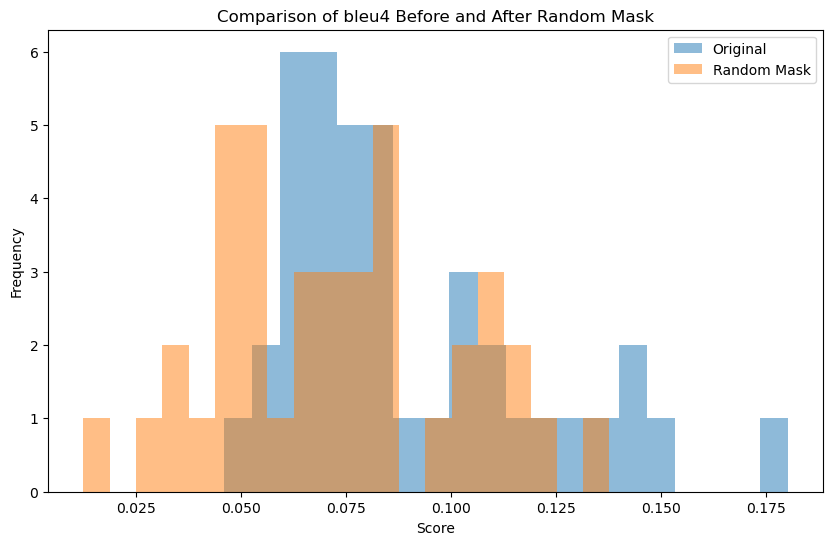

Metric: gpt_bleu4_average vs average_bleu4
T-statistic: 6.1627, P-value: 0.0000



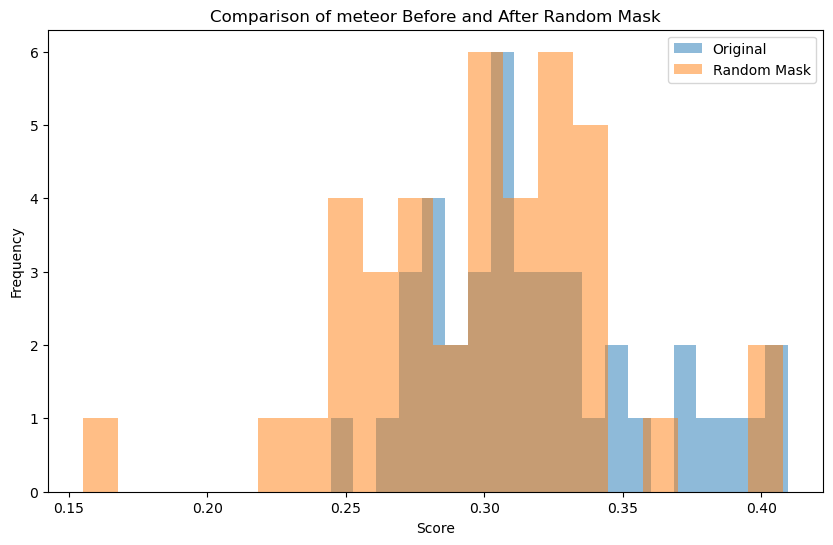

Metric: gpt_meteor_average vs average_meteor
T-statistic: 4.3816, P-value: 0.0001



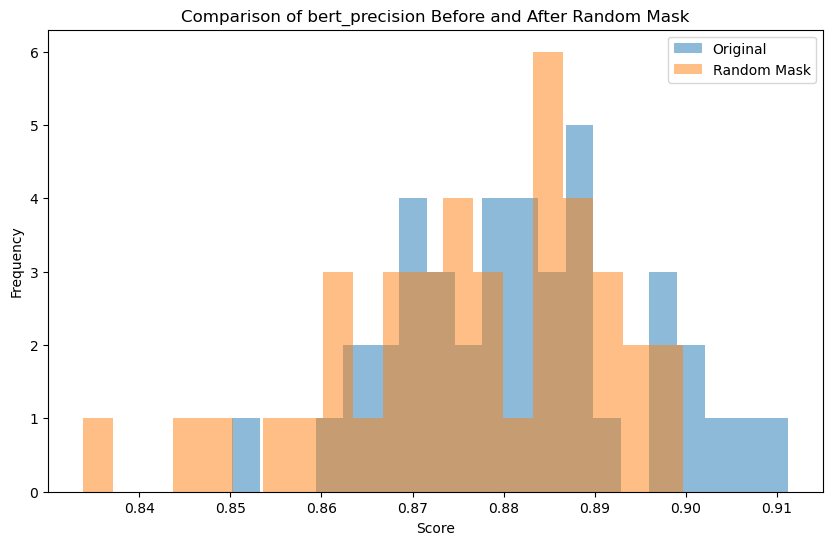

Metric: gpt_bert_precision_average vs average_bert_precision
T-statistic: 5.1702, P-value: 0.0000



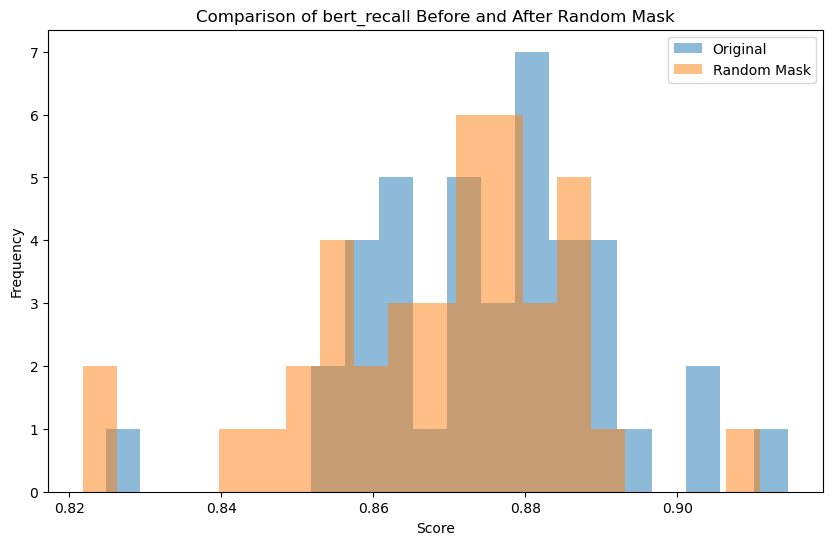

Metric: gpt_bert_recall_average vs average_bert_recall
T-statistic: 6.2286, P-value: 0.0000



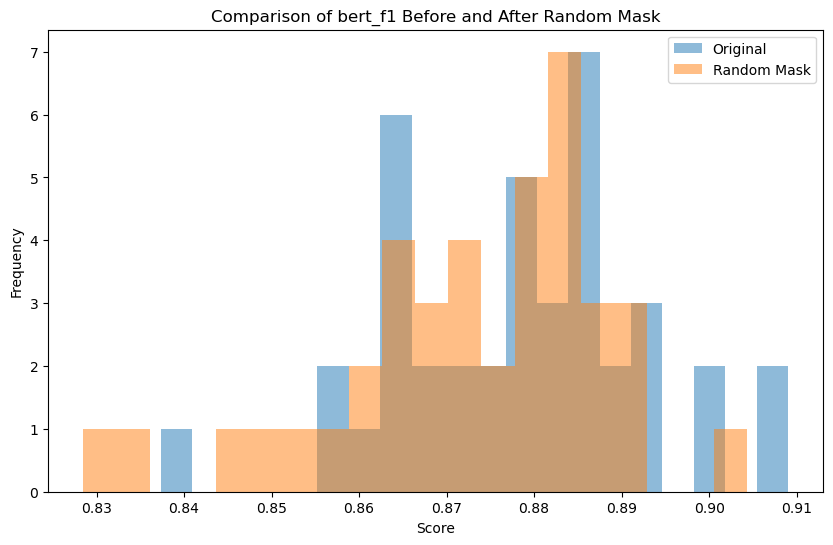

Metric: gpt_bert_f1_average vs average_bert_f1
T-statistic: 5.8316, P-value: 0.0000



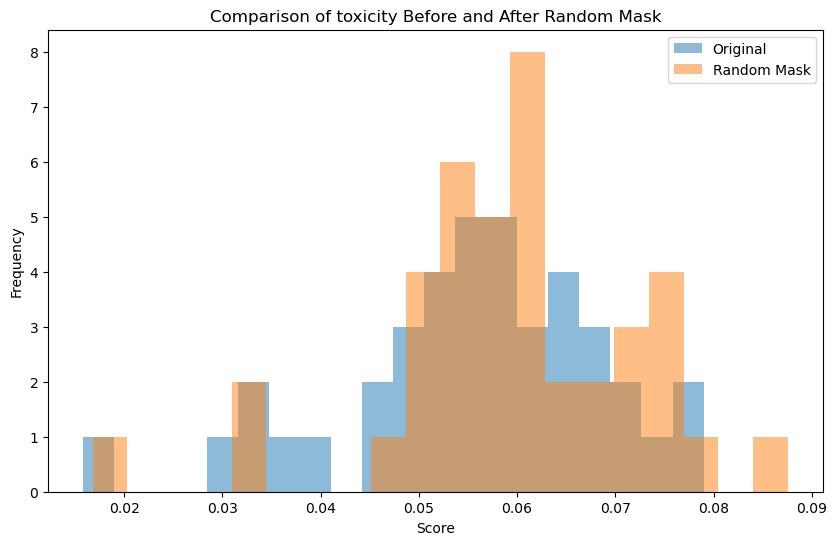

Metric: gpt_toxicity_average vs average_toxicity
T-statistic: -2.6332, P-value: 0.0121



In [ ]:
metrics = [
    ('gpt_rouge1_average', 'average_rouge1'),
    ('gpt_rouge2_average', 'average_rouge2'),
    ('gpt_rouge3_average', 'average_rouge3'),
    ('gpt_rougeL_average', 'average_rougeL'),
    ('gpt_bleu1_average', 'average_bleu1'),
    ('gpt_bleu2_average', 'average_bleu2'),
    ('gpt_bleu3_average', 'average_bleu3'),
    ('gpt_bleu4_average', 'average_bleu4'),
    ('gpt_meteor_average', 'average_meteor'),
    ('gpt_bert_precision_average', 'average_bert_precision'),
    ('gpt_bert_recall_average', 'average_bert_recall'),
    ('gpt_bert_f1_average', 'average_bert_f1'),
    ('gpt_toxicity_average', 'average_toxicity')
]

# Initialize a dictionary to store t-test results
test_results = {}

# Loop through each metric pair
for original, masked in metrics:
    # Plot histogram
    plt.figure(figsize=(10, 6))
    plt.hist(merged_df[original], bins=20, alpha=0.5, label='Original')
    plt.hist(merged_df[masked], bins=20, alpha=0.5, label='Random Mask')
    plt.xlabel('Score')
    plt.ylabel('Frequency')
    plt.title(f'Comparison of {masked.replace("average_", "")} Before and After Random Mask')
    plt.legend()
    plt.show()

    # Conduct paired t-test
    t_stat, p_value = ttest_rel(merged_df[original], merged_df[masked])
    test_results[f'{original} vs {masked}'] = {'t_stat': t_stat, 'p_value': p_value}

    # Display t-test results after each graph
    print(f"Metric: {original} vs {masked}")
    print(f"T-statistic: {t_stat:.4f}, P-value: {p_value:.4f}\n")